# Task 5 — Time Series Preprocessing & Forecasting

Continues from Task 4 (daily cleaned dataset).

```
Task 5 - Time-series preprocessing & forecasting (daily, 10 years): ARIMA / SARIMA(X) + bonus RNN/LSTM
Run:  python task5_forecasting.py                 (everything; LSTM skipped if TensorFlow missing)
      python task5_forecasting.py --skip-lstm
      python task5_forecasting.py --skip-sarima   (only builds the model used by the Django app)

Why not SARIMA with m=365?  A seasonal period of 365 makes statsmodels' SARIMAX explode in memory/time.  The standard
solution for long seasonal periods is "dynamic harmonic regression": model the yearly cycle with Fourier terms (exog)
and let ARIMA handle the remaining short-term dependence.  A true SARIMA(…)(P,D,Q,12) is also fitted on monthly means.
```

## Imports

In [17]:
import json, sys, warnings
import numpy as np, pandas as pd, joblib
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from config import *

warnings.filterwarnings("ignore")
TARGET, TEST_DAYS, K = "temperature", 90, 3          # last 90 days = test; K Fourier pairs for the yearly cycle
FEATURES = ["temperature", "humidity", "wind_speed", "pressure", "doy_sin", "doy_cos"]


def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return dict(MAE=float(mean_absolute_error(y, p)), RMSE=float(np.sqrt(mean_squared_error(y, p))),
                MAPE=float(np.mean(np.abs((y - p) / y)) * 100),
                sMAPE=float(np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p))) * 100))


def savefig(fig, name):
    fig.tight_layout(); fig.savefig(OUT / name, dpi=150); plt.show()


def fourier(index, k=K):
    t = 2 * np.pi * index.dayofyear.values / 365.25
    cols = {"const": np.ones(len(index))}
    for i in range(1, k + 1):
        cols[f"sin{i}"], cols[f"cos{i}"] = np.sin(i * t), np.cos(i * t)
    return pd.DataFrame(cols, index=index)

## 2. Preprocessing

In [18]:
def load_and_preprocess():
    df = pd.read_csv(CLEAN_CSV, parse_dates=["date"], index_col="date").sort_index().asfreq("D")
    assert df.index.freq is not None, "index needs a defined frequency"
    cols = [TARGET, "humidity", "wind_speed", "pressure"]
    print("NaNs introduced by asfreq:", int(df[cols].isna().sum().sum()))
    df[cols] = df[cols].interpolate(method="time", limit=3, limit_direction="both")
    for lag in (7, 365):
        df[cols] = df[cols].fillna(df[cols].shift(lag))
    df[cols] = df[cols].ffill(limit=3).bfill(limit=3)
    # engineered features (ML model behind the Django app / LSTM side)
    df["doy_sin"] = np.sin(2 * np.pi * df.index.dayofyear / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * df.index.dayofyear / 365.25)
    df["lag_1"], df["lag_7"] = df[TARGET].shift(1), df[TARGET].shift(7)
    df["roll_mean_7"], df["roll_std_7"] = df[TARGET].rolling(7).mean(), df[TARGET].rolling(7).std()
    df["roll_mean_30"] = df[TARGET].rolling(30).mean()
    split = df.index.max() - pd.Timedelta(days=TEST_DAYS - 1)      # chronological cut, never shuffled
    train, test = df[df.index < split], df[df.index >= split]
    print(f"train {train.index.min().date()} -> {train.index.max().date()} ({len(train)} days) | test {test.index.min().date()} -> {test.index.max().date()} ({len(test)} days)")
    return df, train, test

## 3. Stationarity + 4.1 ACF/PACF

In [19]:
def stationarity_and_orders(train):
    from statsmodels.tsa.stattools import adfuller, kpss
    from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
    y = train[TARGET].dropna()
    X = fourier(y.index)
    beta = np.linalg.lstsq(X.values, y.values, rcond=None)[0]
    deseason = y - X.values @ beta                                  # remove yearly cycle (Fourier regression)
    series = {"raw": y, "diff(1)": y.diff(1).dropna(), "seasonal diff(365)": y.diff(365).dropna(),
              "deseasonalised (Fourier)": deseason}
    out = {}
    for name, s in series.items():
        adf_p, kpss_p = adfuller(s)[1], kpss(s, regression="c", nlags="auto")[1]
        verdict = ("stationary" if adf_p < .05 and kpss_p >= .05 else
                   "unit root / non-stationary" if adf_p >= .05 and kpss_p < .05 else "tests disagree")
        out[name] = dict(ADF_p=round(adf_p, 4), KPSS_p=round(kpss_p, 4), verdict=verdict)
        print(f"{name:28s} ADF p={adf_p:.4f} KPSS p={kpss_p:.4f} -> {verdict}")
    d = 0 if out["deseasonalised (Fourier)"]["verdict"] == "stationary" else 1
    fig, ax = plt.subplots(2, 2, figsize=(14, 8))
    plot_acf(y, lags=60, ax=ax[0, 0], title="ACF - raw temperature"); plot_pacf(y, lags=60, ax=ax[0, 1], title="PACF - raw temperature", method="ywm")
    plot_acf(deseason, lags=60, ax=ax[1, 0], title="ACF - deseasonalised"); plot_pacf(deseason, lags=60, ax=ax[1, 1], title="PACF - deseasonalised", method="ywm")
    for a in ax.ravel(): a.set_xlabel("Lag (days)")
    savefig(fig, "t5_acf_pacf.png")
    # Manual reading: raw ACF decays very slowly (yearly cycle). After removing it, ACF tails off (AR component) and the PACF cuts
    # off after ~2-3 lags -> AR(2) + a small MA term. Adjust after looking at t5_acf_pacf.png.
    manual = (2, d, 1)
    print("Manual order proposal (p,d,q) with Fourier exog:", manual)
    return out, manual


def run_auto_arima(train):
    try:
        import pmdarima as pm
    except ImportError:
        print("[auto_arima] pmdarima not installed - skipped"); return None
    a = pm.auto_arima(train[TARGET], X=fourier(train.index).drop(columns="const"), seasonal=False, stepwise=True,
                      suppress_warnings=True, error_action="ignore", max_p=4, max_q=4, max_d=1)
    print("auto_arima:", a.order); return dict(order=list(a.order), aic=float(a.aic()))

## 4. ARIMA(X)

In [20]:
def fit_arimax(y, exog, order, start_params=None, maxiter=100):
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    return SARIMAX(y, exog=exog, order=order, enforce_stationarity=False, enforce_invertibility=False).fit(
        disp=False, maxiter=maxiter, start_params=start_params)


def arimax_block(df, train, test, order):
    from statsmodels.stats.diagnostic import acorr_ljungbox
    res, preds = {}, {}
    Ftr, Fte, Fall = fourier(train.index), fourier(test.index), fourier(df.index)
    fit = fit_arimax(train[TARGET], Ftr, order)
    print(fit.summary()); (OUT / "t5_arimax_summary.txt").write_text(str(fit.summary()))
    fig = fit.plot_diagnostics(figsize=(10, 8)); savefig(fig, "t5_arimax_diagnostics.png")
    resid = fit.resid.iloc[order[1] + 1:]
    lb = acorr_ljungbox(resid, lags=[7, 14, 30], return_df=True); print(lb)
    res["ljung_box_p"] = {int(k): float(v) for k, v in lb["lb_pvalue"].items()}; res["aic"], res["bic"] = float(fit.aic), float(fit.bic)

    fc = fit.get_forecast(steps=len(test), exog=Fte); pred = fc.predicted_mean; ci = fc.conf_int(alpha=.05)
    pred.index = ci.index = test.index; preds["ARIMAX + yearly Fourier multi-step"] = pred
    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(train.index[-180:], train[TARGET][-180:], label="train"); ax.plot(test.index, test[TARGET], label="actual")
    ax.plot(test.index, pred, color="crimson", label="forecast")
    ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], color="crimson", alpha=.15, label="95% CI")
    ax.set_title(f"ARIMA{order} + Fourier(K={K}) - forecast vs actual ({TEST_DAYS}-day horizon)")
    ax.set_ylabel("Mean temperature (°C)"); ax.set_xlabel("Date (UTC)"); ax.legend(); savefig(fig, "t5_forecast.png")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(resid.index, resid, lw=.5); ax[0].axhline(0, color="k"); ax[0].set_title("Residuals over time"); ax[0].set_ylabel("°C")
    ax[1].hist(resid, bins=50); ax[1].set_title("Residual histogram"); ax[1].set_xlabel("°C"); savefig(fig, "t5_residuals.png")

    applied = fit.apply(df[TARGET], exog=Fall)                       # one-step-ahead with frozen parameters
    preds["ARIMAX + Fourier one-step"] = applied.get_prediction(start=test.index[0], dynamic=False).predicted_mean

    tscv = TimeSeriesSplit(n_splits=5, test_size=30); maes, horizon = [], []   # walk-forward: 5 rolling 30-day windows
    for tr_i, te_i in tscv.split(df):
        tr, te = df.iloc[tr_i], df.iloc[te_i]
        m = fit_arimax(tr[TARGET], fourier(tr.index), order, start_params=fit.params.values, maxiter=50)
        p = m.get_forecast(steps=len(te), exog=fourier(te.index)).predicted_mean.values
        maes.append(mean_absolute_error(te[TARGET], p)); horizon.append(np.abs(te[TARGET].values - p))
    res["walk_forward_mae_folds"] = [float(x) for x in maes]; res["walk_forward_mae_mean"] = float(np.mean(maes))
    h = np.mean(horizon, axis=0); res["mae_by_horizon"] = [float(x) for x in h]
    fig, ax = plt.subplots(figsize=(8, 4)); ax.plot(range(1, 31), h, marker="o")
    ax.set_title("Forecast error by horizon (walk-forward)"); ax.set_xlabel("Days ahead"); ax.set_ylabel("MAE (°C)")
    savefig(fig, "t5_error_by_horizon.png")
    return res, preds


def arima_nonseasonal(train, test):
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    fit = SARIMAX(train[TARGET], order=(2, 1, 2)).fit(disp=False, maxiter=100)
    p = fit.get_forecast(steps=len(test)).predicted_mean; p.index = test.index; return p


def monthly_sarima(df):
    """A true SARIMA(p,d,q)(P,D,Q,12) on monthly mean temperature; hold out the last 24 months."""
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    m = df[TARGET].resample("MS").mean(); tr, te = m.iloc[:-24], m.iloc[-24:]
    fit = SARIMAX(tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 12), enforce_stationarity=False,
                  enforce_invertibility=False).fit(disp=False)
    p = fit.get_forecast(24); pred, ci = p.predicted_mean, p.conf_int()
    fig, ax = plt.subplots(figsize=(12, 4)); ax.plot(tr.index[-48:], tr[-48:], label="train"); ax.plot(te.index, te, label="actual")
    ax.plot(te.index, pred, color="crimson", label="SARIMA(1,0,1)(1,1,1,12)")
    ax.fill_between(te.index, ci.iloc[:, 0], ci.iloc[:, 1], color="crimson", alpha=.15)
    ax.set_title("SARIMA on monthly mean temperature (m=12) - 24-month forecast"); ax.set_ylabel("°C"); ax.set_xlabel("Month"); ax.legend()
    savefig(fig, "t5_monthly_sarima.png")
    return {"model": "SARIMA(1,0,1)(1,1,1,12), monthly means, 24-month holdout", **{k: round(v, 3) for k, v in metrics(te, pred).items()},
            "aic": float(fit.aic)}

## Baselines

In [21]:
def climatology(train, index):
    c = train[TARGET].groupby(train.index.dayofyear).mean().reindex(range(1, 367)).interpolate()
    ext = pd.concat([c.iloc[-15:], c, c.iloc[:15]]).rolling(15, center=True).mean().iloc[15:-15]   # circular smoothing
    return pd.Series(ext.reindex(index.dayofyear).values, index=index)


def naive_baselines(df, train, test):
    return {"Persistence multi-step": pd.Series(train[TARGET].iloc[-1], index=test.index),
            "Climatology multi-step (train mean by day-of-year)": climatology(train, test.index),
            "Seasonal-naive multi-step (same day last year)": df[TARGET].shift(365).loc[test.index],
            "Persistence one-step": df[TARGET].shift(1).loc[test.index]}

## ML model used by the Django app

In [22]:
def train_feature_model(df, train, test):
    """Predict NEXT-DAY mean temperature from today's mean conditions + day of year - this is what the Django form feeds."""
    X, y = df[FEATURES], df[TARGET].shift(-1); ok = y.notna()
    tr_m, te_m = (df.index < test.index[0]) & ok, (df.index >= test.index[0]) & ok
    Xtr, ytr, Xte, yte = X[tr_m], y[tr_m], X[te_m], y[te_m]
    cands = {"Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
             "GradientBoosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=.05, random_state=42)}
    scores = {}
    for name, m in cands.items():
        m.fit(Xtr, ytr); scores[name] = metrics(yte, m.predict(Xte)); print(f"{name}: {scores[name]}")
    best_name = min(scores, key=lambda k: scores[k]["MAE"]); best = cands[best_name]
    sample = Xte.iloc[0]
    payload = dict(model=best, model_name=best_name, features=FEATURES, target="Mean temperature tomorrow (°C)",
                   resid_std=float(np.std(yte - best.predict(Xte))), metrics=scores[best_name], city=CITY,
                   trained_through=str(Xtr.index.max().date()),
                   train_ranges={c: [float(Xtr[c].min()), float(Xtr[c].max())] for c in FEATURES},
                   sample_input={c: float(sample[c]) for c in FEATURES}, sample_day_of_year=int(Xte.index[0].dayofyear),
                   sample_prediction=float(best.predict(sample.to_frame().T)[0]))
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True); joblib.dump(payload, MODEL_PATH)
    print(f"[saved] {MODEL_PATH} ({best_name}, test MAE {scores[best_name]['MAE']:.3f} °C)")
    return payload, pd.Series(best.predict(Xte), index=yte.index)

## Bonus: RNN / LSTM

In [23]:
def lstm_block(df, train, test, n_steps=30):
    try:
        import tensorflow as tf
        from tensorflow.keras.models import Sequential
        from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Dropout, Input
        from tensorflow.keras.callbacks import EarlyStopping
        from sklearn.preprocessing import MinMaxScaler
    except ImportError:
        print("[LSTM] TensorFlow not installed - bonus skipped"); return {}, None
    tf.random.set_seed(42); np.random.seed(42)
    scaler = MinMaxScaler().fit(train[[TARGET]])                       # fit ONLY on train
    tr_s = scaler.transform(train[[TARGET]]).ravel()
    te_s = scaler.transform(pd.concat([train[TARGET].iloc[-n_steps:], test[TARGET]]).to_frame()).ravel()   # context for 1st window

    def windows(s):
        X = np.array([s[i:i + n_steps] for i in range(len(s) - n_steps)]); return X.reshape(-1, n_steps, 1), s[n_steps:]
    Xtr, ytr = windows(tr_s); Xte, _ = windows(te_s)
    es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    rnn = Sequential([Input((n_steps, 1)), SimpleRNN(32), Dense(1)]); rnn.compile("adam", "mse")
    rnn.fit(Xtr, ytr, validation_split=.1, epochs=50, batch_size=32, callbacks=[es], verbose=0)
    lstm = Sequential([Input((n_steps, 1)), LSTM(64, return_sequences=True), Dropout(.2), LSTM(32), Dense(1)]); lstm.compile("adam", "mse")
    hist = lstm.fit(Xtr, ytr, validation_split=.1, epochs=50, batch_size=32, callbacks=[es], verbose=0)
    fig, ax = plt.subplots(figsize=(7, 4)); ax.plot(hist.history["loss"], label="train"); ax.plot(hist.history["val_loss"], label="val")
    ax.set_title("LSTM training curve"); ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (scaled)"); ax.legend(); savefig(fig, "t5_lstm_loss.png")
    out = {name: pd.Series(scaler.inverse_transform(m.predict(Xte, verbose=0)).ravel(), index=test.index)   # inverse-transform BEFORE metrics
           for name, m in {"Simple RNN one-step": rnn, "LSTM one-step": lstm}.items()}
    return out, hist

## Compare + report

In [24]:
def report(test, all_preds, extra):
    rows = []
    for name, p in all_preds.items():
        y = test[TARGET].shift(-1) if "next-day" in name else test[TARGET]    # feature model at day t predicts day t+1
        y = y.reindex(p.index).dropna(); p = p.reindex(y.index)
        rows.append({"Model": name, **{k: round(v, 3) for k, v in metrics(y, p).items()}})
    tab = pd.DataFrame(rows).sort_values("MAE"); tab.to_csv(OUT / "t5_model_comparison.csv", index=False); print(tab.to_string(index=False))
    fig, ax = plt.subplots(figsize=(10, 5)); ax.barh(tab["Model"], tab["MAE"], color="#2563eb"); ax.invert_yaxis()
    ax.set_title("Model comparison - MAE (°C) on held-out test set"); ax.set_xlabel(f"MAE (°C)   [multi-step = {TEST_DAYS}-day recursive; one-step / next-day = 1 day ahead]")
    savefig(fig, "t5_model_comparison.png")
    multi = tab[tab["Model"].str.contains("multi-step")]; one = tab[tab["Model"].str.contains("one-step|next-day")]
    md = tab.to_markdown(index=False) if _has_tabulate() else tab.to_string(index=False)
    txt = f"""# Task 5 - Conclusion
Test set = last {TEST_DAYS} days (chronological split, no shuffling). Metrics in °C.

{md}

**Multi-step ({TEST_DAYS}-day) winner:** {multi.iloc[0]['Model'] if len(multi) else 'n/a'} (MAE {multi.iloc[0]['MAE'] if len(multi) else 'n/a'} °C).
**One-step (next day) winner:** {one.iloc[0]['Model'] if len(one) else 'n/a'} (MAE {one.iloc[0]['MAE'] if len(one) else 'n/a'} °C).

One-step and multi-step numbers are not comparable: one-step models see the real previous days, multi-step models must extrapolate {TEST_DAYS} days.
Daily temperature is very persistent, so one-step persistence is a strong baseline - a model must beat it to be useful. Over a long horizon
the ARIMAX forecast converges to the seasonal (Fourier) curve, so it can't know about individual heat waves; that is why its interval widens
and why it behaves like the climatology baseline.
ARIMAX diagnostics: Ljung-Box p-values {extra.get('ljung_box_p')}; walk-forward mean MAE (30-day horizon) = {extra.get('walk_forward_mae_mean')}.
Monthly SARIMA (m=12): {extra.get('monthly_sarima')}.
"""
    (OUT / "conclusion_task5.md").write_text(txt, encoding="utf-8")


def _has_tabulate():
    try:
        import tabulate  # noqa
        return True
    except ImportError:
        return False

## ▶ Run the pipeline
Run **Task 4 first** (it creates `data/weather_clean.csv`). Then run these cells in order.

In [25]:
df, train, test = load_and_preprocess()
df.tail()

NaNs introduced by asfreq: 0
train 2016-10-16 -> 2026-07-17 (3562 days) | test 2026-07-18 -> 2026-10-15 (90 days)


,temperature,humidity,wind_speed,pressure,cloud_cover,precipitation,temp_max,temp_min,temperature_outlier,wind_speed_outlier,pressure_outlier,doy_sin,doy_cos,lag_1,lag_7,roll_mean_7,roll_std_7,roll_mean_30
date,,,,,,,,,,,,,,,,,,
2026-10-11,24.025000,48.125000,6.725000,1010.629167,34.791667,0.0,29.2,19.2,0,0,0,-0.985056,0.172236,24.883333,24.512500,24.589881,0.294105,27.022500
2026-10-12,24.341667,49.375000,7.100000,1012.204167,11.166667,0.0,30.8,18.1,0,0,0,-0.981947,0.189155,24.025000,24.491667,24.568452,0.307609,26.860972
2026-10-13,25.145833,56.833333,7.979167,1013.475000,82.750000,0.0,30.7,18.9,0,0,0,-0.978548,0.206018,24.341667,24.487500,24.662500,0.372523,26.699722
2026-10-14,26.466667,46.000000,9.637500,1010.575000,28.583333,0.0,33.0,20.9,0,0,0,-0.974860,0.222820,25.145833,24.670833,24.919048,0.777482,26.580694
2026-10-15,23.745833,50.958333,7.741667,1011.725000,19.958333,0.0,28.7,18.8,0,0,0,-0.970882,0.239557,26.466667,24.712500,24.780952,0.896953,26.364583


### Model used by the Django app (next-day temperature) + naive baselines

In [26]:
payload, feat_pred = train_feature_model(df, train, test)
preds = naive_baselines(df, train, test)
preds['Feature model next-day (Django model)'] = feat_pred
extra = {}

Ridge: {'MAE': 0.692402043404948, 'RMSE': 0.8763152902800676, 'MAPE': 2.3944842453694752, 'sMAPE': 2.3718868152232533}
GradientBoosting: {'MAE': 0.6964407788366275, 'RMSE': 0.9095992478347052, 'MAPE': 2.4208551757880556, 'sMAPE': 2.3917301663151442}
[saved] C:\Users\noura\Weather_Time_Series_EDA\data\task5_feature_model.joblib (Ridge, test MAE 0.692 °C)


### Stationarity (ADF + KPSS), ACF/PACF and order selection

raw                          ADF p=0.0039 KPSS p=0.1000 -> stationary
diff(1)                      ADF p=0.0000 KPSS p=0.1000 -> stationary
seasonal diff(365)           ADF p=0.0000 KPSS p=0.1000 -> stationary
deseasonalised (Fourier)     ADF p=0.0000 KPSS p=0.0100 -> tests disagree


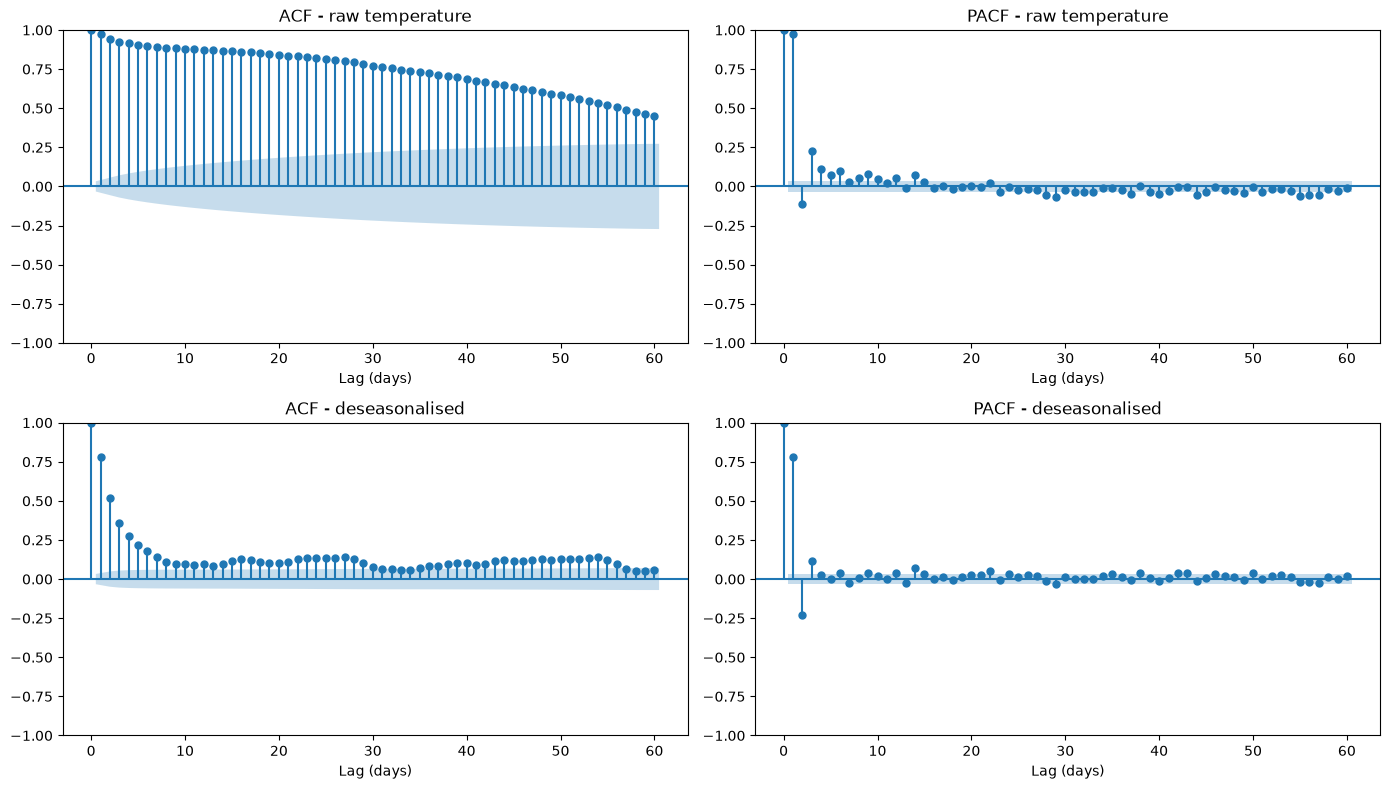

Manual order proposal (p,d,q) with Fourier exog: (2, 1, 1)
[auto_arima] pmdarima not installed - skipped
Manual order: (2, 1, 1) | auto_arima: None


,ADF_p,KPSS_p,verdict
raw,0.0039,0.1,stationary
diff(1),0.0,0.1,stationary
seasonal diff(365),0.0,0.1,stationary
deseasonalised (Fourier),0.0,0.01,tests disagree


In [27]:
tests, manual = stationarity_and_orders(train)
auto = run_auto_arima(train)      # skipped automatically if pmdarima isn't installed
print('Manual order:', manual, '| auto_arima:', auto)
pd.DataFrame(tests).T

### ARIMAX + yearly Fourier terms: fit, diagnostics, forecast, walk-forward

                               SARIMAX Results                                
Dep. Variable:            temperature   No. Observations:                 3562
Model:               SARIMAX(2, 1, 1)   Log Likelihood               -6078.465
Date:                Fri, 06 Nov 2026   AIC                          12178.931
Time:                        11:57:05   BIC                          12246.880
Sample:                    10-16-2016   HQIC                         12203.160
                         - 07-17-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const       6.177e-08    4.2e-09     14.698      0.000    5.35e-08       7e-08
sin1          -3.4049      0.164    -20.734      0.000      -3.727      -3.083
cos1          -7.8929      0.153    -51.517      0.0

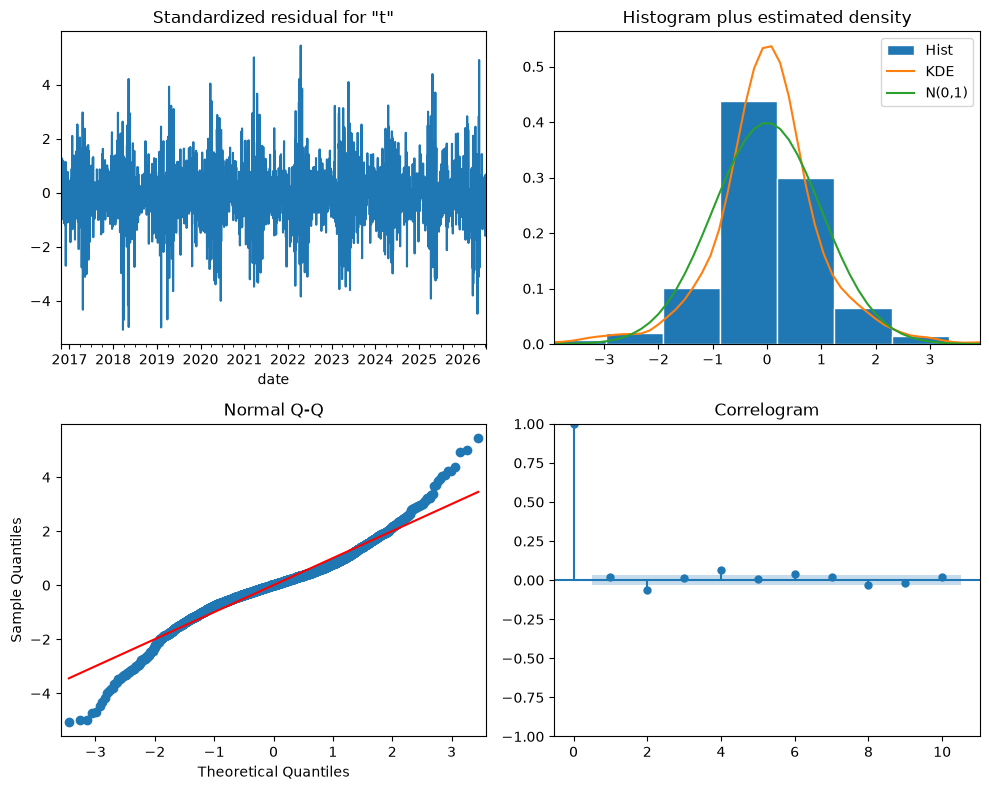

      lb_stat     lb_pvalue
7   35.950155  7.407983e-06
14  57.377319  3.364686e-07
30  77.739096  4.154414e-06


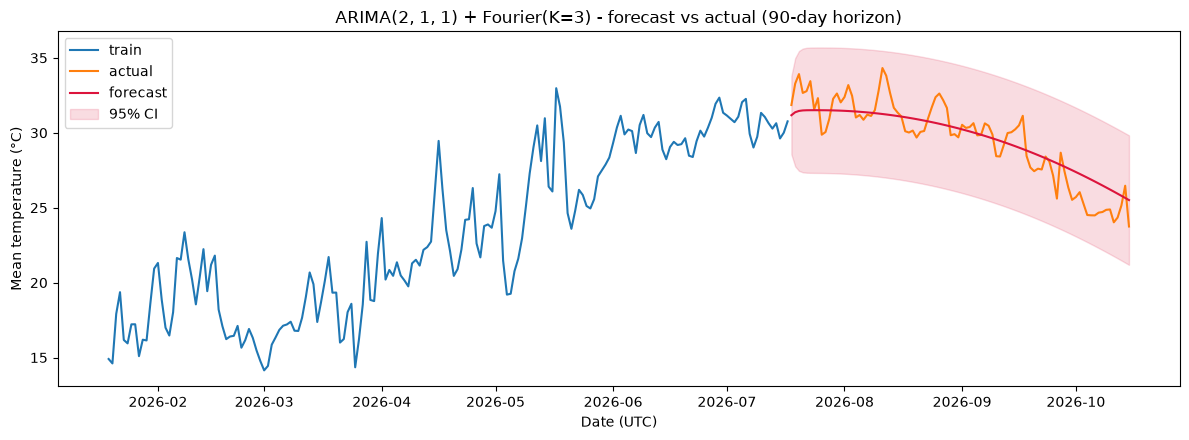

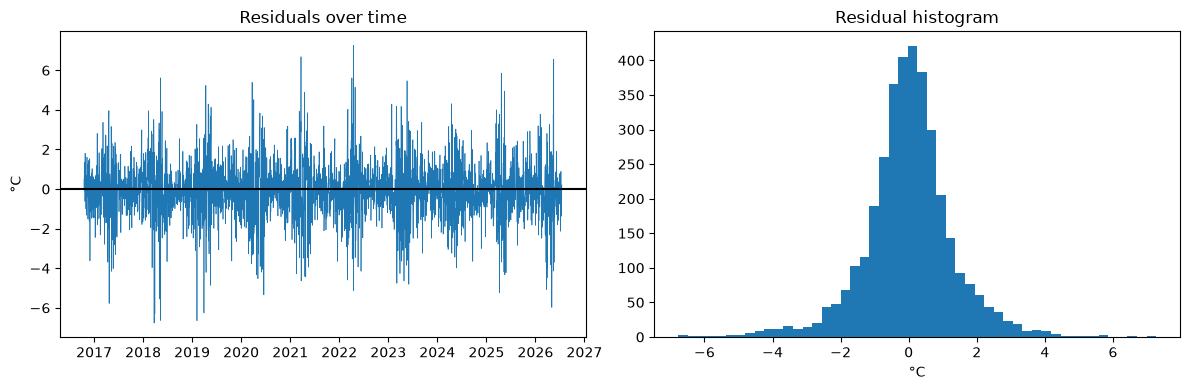

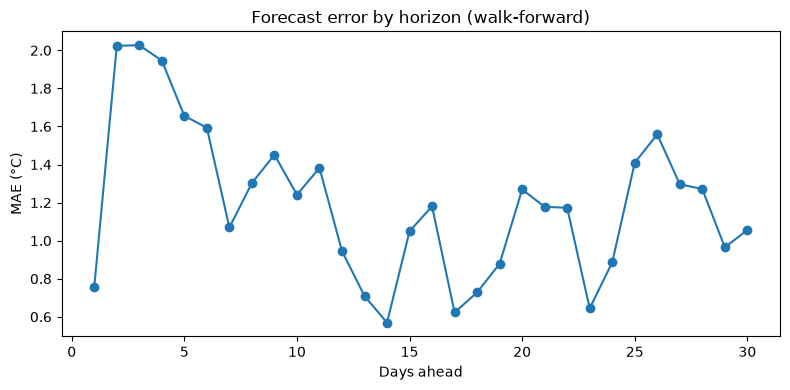

In [28]:
extra, sp = arimax_block(df, train, test, manual)
preds.update(sp)
preds['ARIMA (2,1,2) non-seasonal multi-step'] = arima_nonseasonal(train, test)

### True SARIMA (m=12) on monthly means

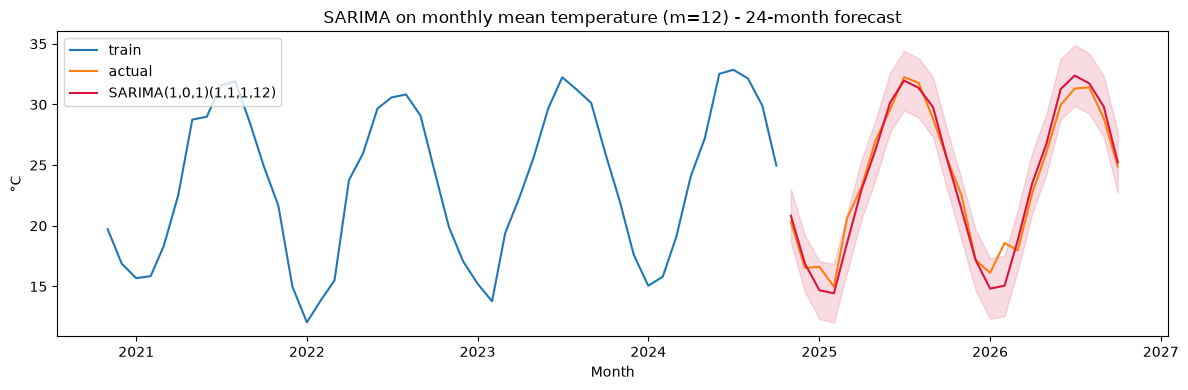

{'model': 'SARIMA(1,0,1)(1,1,1,12), monthly means, 24-month holdout',
 'MAE': 0.873,
 'RMSE': 1.154,
 'MAPE': 4.073,
 'sMAPE': 4.209,
 'aic': 229.84139088100954}

In [29]:
extra.update(stationarity=tests, manual_order=list(manual), auto_arima=auto, monthly_sarima=monthly_sarima(df))
extra['monthly_sarima']

### (Bonus) RNN / LSTM — skipped automatically if TensorFlow isn't installed

In [30]:
lp, hist = lstm_block(df, train, test)
preds.update(lp)

[LSTM] TensorFlow not installed - bonus skipped


### Model comparison and conclusion

                                             Model   MAE  RMSE  MAPE  sMAPE
                         ARIMAX + Fourier one-step 0.659 0.870 2.266  2.253
                              Persistence one-step 0.690 0.939 2.351  2.337
             Feature model next-day (Django model) 0.692 0.876 2.394  2.372
Climatology multi-step (train mean by day-of-year) 1.010 1.218 3.496  3.473
                ARIMAX + yearly Fourier multi-step 1.062 1.278 3.681  3.657
    Seasonal-naive multi-step (same day last year) 1.398 1.787 4.769  4.686
             ARIMA (2,1,2) non-seasonal multi-step 2.201 2.925 8.018  7.559
                            Persistence multi-step 2.245 2.995 8.208  7.701


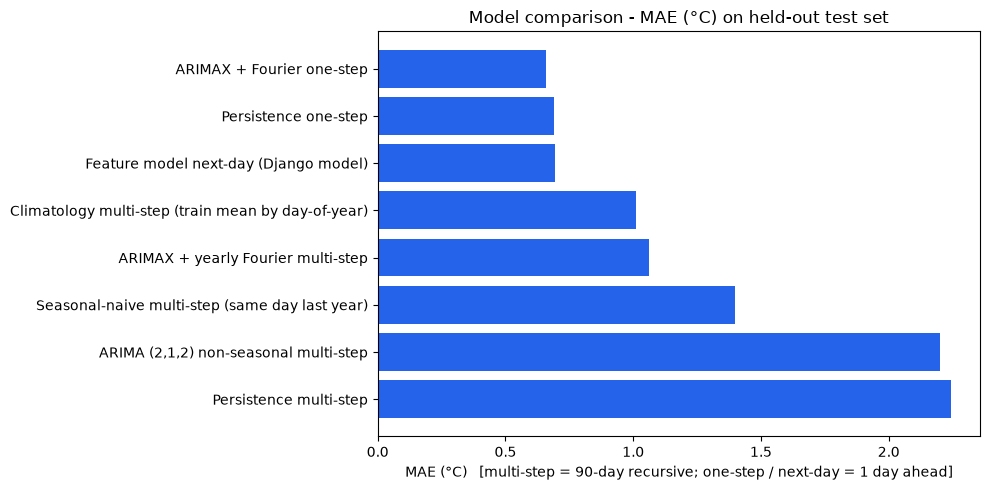

,Model,MAE,RMSE,MAPE,sMAPE
0,ARIMAX + Fourier one-step,0.659,0.870,2.266,2.253
1,Persistence one-step,0.690,0.939,2.351,2.337
2,Feature model next-day (Django model),0.692,0.876,2.394,2.372
3,Climatology multi-step (train mean by day-of-y...,1.010,1.218,3.496,3.473
4,ARIMAX + yearly Fourier multi-step,1.062,1.278,3.681,3.657
5,Seasonal-naive multi-step (same day last year),1.398,1.787,4.769,4.686
6,"ARIMA (2,1,2) non-seasonal multi-step",2.201,2.925,8.018,7.559
7,Persistence multi-step,2.245,2.995,8.208,7.701


In [31]:
report(test, preds, extra)
(OUT / 't5_results.json').write_text(json.dumps(extra, indent=1, default=str))
pd.read_csv(OUT / 't5_model_comparison.csv')

In [32]:
print((OUT / 'conclusion_task5.md').read_text(encoding='utf-8'))

# Task 5 - Conclusion
Test set = last 90 days (chronological split, no shuffling). Metrics in °C.

| Model                                              |   MAE |   RMSE |   MAPE |   sMAPE |
|:---------------------------------------------------|------:|-------:|-------:|--------:|
| ARIMAX + Fourier one-step                          | 0.659 |  0.87  |  2.266 |   2.253 |
| Persistence one-step                               | 0.69  |  0.939 |  2.351 |   2.337 |
| Feature model next-day (Django model)              | 0.692 |  0.876 |  2.394 |   2.372 |
| Climatology multi-step (train mean by day-of-year) | 1.01  |  1.218 |  3.496 |   3.473 |
| ARIMAX + yearly Fourier multi-step                 | 1.062 |  1.278 |  3.681 |   3.657 |
| Seasonal-naive multi-step (same day last year)     | 1.398 |  1.787 |  4.769 |   4.686 |
| ARIMA (2,1,2) non-seasonal multi-step              | 2.201 |  2.925 |  8.018 |   7.559 |
| Persistence multi-step                             | 2.245 |  2.995 |  8.208 |  